# Physics-informed neural networks (PINNs) – an introduction with worked examples

A PINN is an ordinary neural network $\hat x(t;\theta)$ (or $\hat u(x,t;\theta)$) whose training loss contains, besides the usual data misfit, the **residual of the governing differential equation**. The derivatives in that residual are not computed by finite differences but exactly, by automatic differentiation of the network with respect to its *inputs*.

$$
\mathcal L(\theta) \;=\; \underbrace{\frac1{N_d}\sum_i \big(\hat x(t_i)-x_i\big)^2}_{\text{data (measurements)}}
\;+\;\lambda\,\underbrace{\frac1{N_c}\sum_j \mathcal R\big[\hat x\big](t_j)^2}_{\text{physics at collocation points}}
\;+\;\text{(initial / boundary conditions)}
$$

For a mass–spring–damper, $\mathcal R[\hat x] = m\hat x'' + c\hat x' + k\hat x - F(t)$. The collocation points $t_j$ are just places in the domain where the equation is enforced; they need no measurements. Unknown physical parameters ($c$, $k$, a diffusivity …) or even unknown *functions* (a damper characteristic) can be made trainable alongside the network weights – that is what makes PINNs interesting for model calibration.

**What this notebook covers**

| # | Example | What it shows |
|---|---|---|
| 1 | Derivatives of a network | `torch.autograd.grad` w.r.t. inputs; why ReLU is useless for PINNs |
| 2 | Damped oscillator, forward | plain NN vs. PINN extrapolation; PINN as an ODE "solver"; hard initial conditions; cost compared to `solve_ivp` |
| 3 | Damped oscillator, inverse | identify $c$ and $k$ from 30 noisy samples; compare with classical least squares |
| 4 | Missing physics | learn an unknown, asymmetric damper characteristic $F_d(v)$ from displacement data only |
| 5 | 1-D heat equation, inverse | reconstruct a whole temperature field *and* the diffusivity from three sensors |
| 6 | Assessment | when PINNs are worth it for vehicle-dynamics / engine work, and when not |

Everything runs on a laptop CPU (total ≈ 5 min; each training loop prints its time). Setup: `pip install numpy scipy matplotlib torch`.

In [1]:
import time
import numpy as np
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

torch.set_default_dtype(torch.float64)   # PINNs differentiate twice -> double precision avoids noise
torch.set_num_threads(min(4, torch.get_num_threads()))

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # same palette as Calibration_Optimization
INK, MUTED = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "white", "axes.prop_cycle": cycler(color=C),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.8,
    "legend.frameon": False, "legend.fontsize": 9, "figure.constrained_layout.use": True,
})
REF = dict(color=MUTED, lw=1.2, ls="--")          # style for exact / reference solutions

Two small helpers are used throughout: a fully connected network and a one-liner for the derivative of a network output with respect to its input. `create_graph=True` keeps the derivative itself differentiable, which is needed (a) for second derivatives and (b) because the optimiser has to differentiate the *residual* with respect to the weights.

In [2]:
class MLP(torch.nn.Module):
    # n_in -> [width, tanh] x depth -> n_out
    def __init__(self, n_in=1, n_out=1, width=32, depth=3, act=torch.nn.Tanh):
        super().__init__()
        layers, d = [], n_in
        for _ in range(depth):
            layers += [torch.nn.Linear(d, width), act()]
            d = width
        layers.append(torch.nn.Linear(d, n_out))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


def d(y, x):
    # dy/dx for a batch where y[i] depends only on x[i]
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]


def train(params, loss_fn, n_iter, lr=2e-3, log_every=100, lr_decay=None):
    # Adam loop; loss_fn() returns (total_loss, dict_of_parts). Returns a history dict of arrays.
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, lr_decay) if lr_decay else None
    hist, t0 = {}, time.perf_counter()
    for it in range(n_iter):
        opt.zero_grad()
        loss, parts = loss_fn()
        loss.backward()
        opt.step()
        if sched and (it + 1) % 1000 == 0:
            sched.step()
        if it % log_every == 0 or it == n_iter - 1:
            hist.setdefault("iter", []).append(it)
            for k, v in parts.items():
                hist.setdefault(k, []).append(float(v.detach()) if torch.is_tensor(v) else float(v))
    hist = {k: np.array(v) for k, v in hist.items()}
    hist["time"] = time.perf_counter() - t0
    return hist


def to_t(a):
    return torch.as_tensor(np.asarray(a, dtype=float)).reshape(-1, 1)

## 1  Derivatives of a neural network

A network with smooth activations is a smooth function of its input, so $d\hat x/dt$ and $d^2\hat x/dt^2$ exist everywhere and autograd gives them exactly (to round-off), at the cost of roughly one extra backward pass per derivative order. A quick check on a function with a known derivative, then the same on an *untrained* tanh and ReLU network:

max |dy/dt - 3cos(3t)|     = 0.0
max |d2y/dt2 + 9 sin(3t)|  = 1.7763568394002505e-15


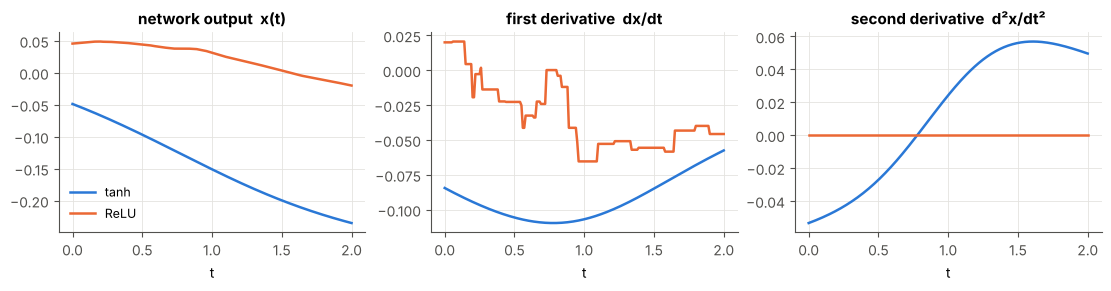

In [3]:
t = torch.linspace(0, 2, 201).reshape(-1, 1).requires_grad_(True)
y = torch.sin(3 * t)
dy, d2y = d(y, t), d(d(y, t), t)
print("max |dy/dt - 3cos(3t)|     =", float((dy - 3 * torch.cos(3 * t)).abs().max().detach()))
print("max |d2y/dt2 + 9 sin(3t)|  =", float((d2y + 9 * torch.sin(3 * t)).abs().max().detach()))

torch.manual_seed(1)
fig, axs = plt.subplots(1, 3, figsize=(11, 2.8))
for act, col, name in [(torch.nn.Tanh, C[0], "tanh"), (torch.nn.ReLU, C[1], "ReLU")]:
    net = MLP(act=act)
    x = net(t)
    for ax, val in zip(axs, [x, d(x, t), d(d(x, t), t)]):
        ax.plot(t.detach(), val.detach(), color=col, label=name)
for ax, ttl in zip(axs, ["network output  x(t)", "first derivative  dx/dt", "second derivative  d²x/dt²"]):
    ax.set_title(ttl); ax.set_xlabel("t")
axs[0].legend()
plt.show()

The ReLU network is piecewise linear: its first derivative is piecewise constant and its **second derivative is zero almost everywhere**. A residual such as $m\hat x''+c\hat x'+k\hat x$ would never see the inertia term. That is why PINNs use smooth activations – `tanh` is the standard choice, `SiLU`/`sin` are alternatives.

## 2  Forward problem: a damped oscillator

Take the free decay of a single-mass oscillator – think of a quarter-car body mode at $f_n = 1.5$ Hz with damping ratio $\zeta = 0.15$, released from an initial deflection (normalised to 1) at rest:

$$\ddot x + 2\zeta\omega_0\dot x + \omega_0^2 x = 0,\qquad x(0)=1,\ \dot x(0)=0,\qquad \omega_0 = 2\pi f_n .$$

The exact solution is known, so every result can be checked. We pretend we have measured only the **first 0.7 s** (12 samples) and want the response up to 2 s.

**Scaling matters.** The network input is mapped to $[-1,1]$ inside the model, and the residual is divided by $\omega_0^2$, so that all three terms are $\mathcal O(1)$. Without this the physics term would be ~90× larger than the data term and the weighting $\lambda$ would have to absorb it. Non-dimensionalising the equation is the first thing to do in any PINN.

In [4]:
f_n, zeta = 1.5, 0.15
w0 = 2 * np.pi * f_n
wd = w0 * np.sqrt(1 - zeta**2)
T_END = 2.0

def x_exact(t):
    return np.exp(-zeta * w0 * t) * (np.cos(wd * t) + zeta * w0 / wd * np.sin(wd * t))

t_plot = np.linspace(0, T_END, 400)
t_data = np.linspace(0, 0.7, 12)
x_data = x_exact(t_data)

class Oscillator(torch.nn.Module):
    # x_hat(t): input scaling to [-1, 1] lives inside the model, so autograd w.r.t. t stays correct
    def __init__(self, hard_ic=False, **kw):
        super().__init__()
        self.net, self.hard_ic = MLP(**kw), hard_ic
    def forward(self, t):
        z = self.net(2 * t / T_END - 1)
        if self.hard_ic:                 # x(0)=1 and x'(0)=0 hold for ANY network output
            s = 1 - torch.exp(-w0 * t)
            return 1 + s**2 * z
        return z

def residual(model, t):
    x = model(t)
    xt = d(x, t)
    xtt = d(xt, t)
    return xtt / w0**2 + 2 * zeta / w0 * xt + x      # equation divided by w0^2 -> O(1) terms

T_d, X_d = to_t(t_data), to_t(x_data)
T_c = to_t(np.linspace(0, T_END, 200)).requires_grad_(True)     # collocation points

### 2a  Plain network vs. PINN, same 12 data points

The plain network minimises only the data misfit. The PINN additionally penalises the ODE residual at 200 collocation points spread over the *whole* interval $[0, 2]$ s – including the part without any measurement.

In [5]:
torch.manual_seed(0)
nn_plain = Oscillator()
h_plain = train(list(nn_plain.parameters()),
                lambda: ((l := ((nn_plain(T_d) - X_d) ** 2).mean()), {"data": l}),
                n_iter=4000)

torch.manual_seed(0)
pinn = Oscillator()
lam = 1.0
def loss_pinn():
    l_d = ((pinn(T_d) - X_d) ** 2).mean()
    l_p = (residual(pinn, T_c) ** 2).mean()
    return l_d + lam * l_p, {"data": l_d, "physics": l_p}
h_pinn = train(list(pinn.parameters()), loss_pinn, n_iter=15000, lr_decay=0.85)
print(f"plain NN: {h_plain['time']:.1f} s     PINN: {h_pinn['time']:.1f} s")

plain NN: 2.9 s     PINN: 41.9 s


RMS error on [0, 2] s   plain NN: 0.177   PINN: 0.0018


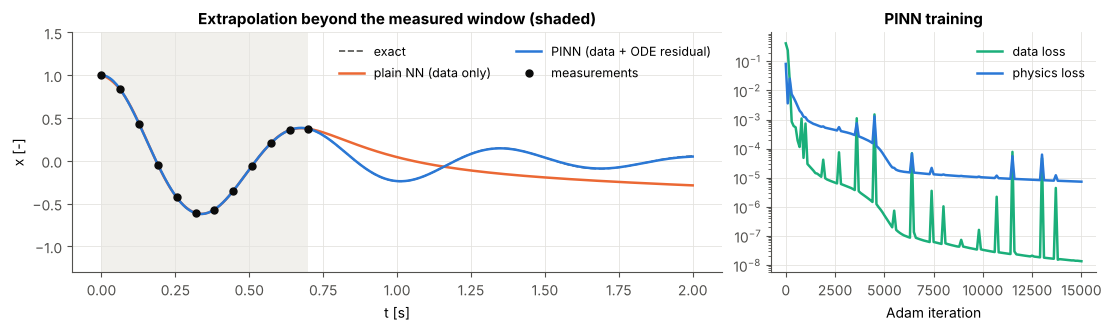

In [6]:
Tp = to_t(t_plot)
with torch.no_grad():
    x_plain, x_pinn = nn_plain(Tp).numpy().ravel(), pinn(Tp).numpy().ravel()
err = lambda xh: np.sqrt(np.mean((xh - x_exact(t_plot)) ** 2))
print(f"RMS error on [0, 2] s   plain NN: {err(x_plain):.3f}   PINN: {err(x_pinn):.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2, 1]})
ax = axs[0]
ax.axvspan(0, 0.7, color="#f1f0ec", lw=0)
ax.plot(t_plot, x_exact(t_plot), **REF, label="exact")
ax.plot(t_plot, x_plain, color=C[1], label="plain NN (data only)")
ax.plot(t_plot, x_pinn, color=C[0], label="PINN (data + ODE residual)")
ax.plot(t_data, x_data, "o", color=INK, ms=5, label="measurements")
ax.set_ylim(-1.3, 1.5); ax.set_xlabel("t [s]"); ax.set_ylabel("x [-]")
ax.set_title("Extrapolation beyond the measured window (shaded)"); ax.legend(ncol=2, loc="upper right")
ax = axs[1]
ax.semilogy(h_pinn["iter"], h_pinn["data"], color=C[2], label="data loss")
ax.semilogy(h_pinn["iter"], h_pinn["physics"], color=C[0], label="physics loss")
ax.set_xlabel("Adam iteration"); ax.set_title("PINN training"); ax.legend()
plt.show()

Inside the shaded window both networks fit the data. Outside it, the plain network continues with whatever shape is cheapest – there is no information there. The PINN has the equation as information: the residual at the collocation points forces the continuation to be a solution of the ODE, and the measured window pins down *which* solution.

The loss history shows two things typical for PINNs: the physics loss settles about two orders of magnitude above the data loss (the residual is the harder target), and Adam produces occasional spikes, which the decaying learning rate damps out. Plot the two terms separately – the total alone hides which one is not converging.

Information propagates through the residual **from the data (or the initial condition) outward**: the network has to get the first oscillations right before the later ones can be right. This "causality" is the main reason long time horizons are hard for PINNs (see exercise 2).

### 2b  PINN as a pure ODE solver (no data) – and hard initial conditions

With known initial conditions no data are needed at all: the loss is only the residual plus the initial conditions. Even better, the initial conditions can be built into the network **exactly**:

$$\hat x(t) = 1 + s(t)^2\, N(t;\theta),\qquad s(t) = 1-e^{-\omega_0 t} \quad\Rightarrow\quad \hat x(0)=1,\ \hat x'(0)=0\ \text{ for any } \theta .$$

This "hard constraint" removes a loss term and its weight. The same trick works for boundary conditions in PDEs (section 5).

The hard constraint must be **well scaled** too. The more obvious choice $s(t) = t/T$ is also exact, but near $t=0$ the network then has to output $(\hat x - 1)/(t/T)^2 \to -\omega_0^2T^2/2 \approx -180$, while it starts with outputs of order 1. In a test run with that version the PINN converged to a visibly phase-shifted solution (RMS error 0.14). With $s(t) = 1-e^{-\omega_0 t}$, which rises on the time scale of the dynamics, the network only has to output $\mathcal O(1)$ values.

PINN (no data):  RMS error 8.8e-04   training time 47.3 s
solve_ivp RK45:  RMS error 2.1e-09   run time      13.8 ms


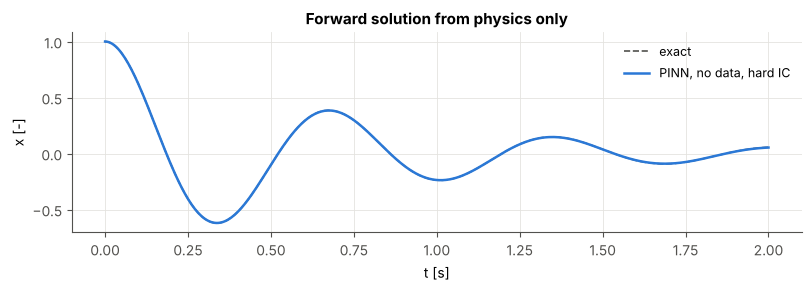

In [7]:
torch.manual_seed(0)
pinn_fwd = Oscillator(hard_ic=True)
h_fwd = train(list(pinn_fwd.parameters()),
              lambda: ((l := (residual(pinn_fwd, T_c) ** 2).mean()), {"physics": l}),
              n_iter=15000, lr_decay=0.85)
with torch.no_grad():
    x_fwd = pinn_fwd(Tp).numpy().ravel()

t0 = time.perf_counter()
for _ in range(20):
    sol = solve_ivp(lambda t, y: [y[1], -2 * zeta * w0 * y[1] - w0**2 * y[0]], (0, T_END), [1, 0],
                    t_eval=t_plot, rtol=1e-8, atol=1e-10)
t_ivp = (time.perf_counter() - t0) / 20

print(f"PINN (no data):  RMS error {err(x_fwd):.1e}   training time {h_fwd['time']:.1f} s")
print(f"solve_ivp RK45:  RMS error {err(sol.y[0]):.1e}   run time      {1e3 * t_ivp:.1f} ms")

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(t_plot, x_exact(t_plot), **REF, label="exact")
ax.plot(t_plot, x_fwd, color=C[0], label="PINN, no data, hard IC")
ax.set_xlabel("t [s]"); ax.set_ylabel("x [-]"); ax.legend(); ax.set_title("Forward solution from physics only")
plt.show()

This comparison is the honest baseline for everything that follows: **as a plain forward solver for an ODE, a PINN is several orders of magnitude slower and less accurate than a classical integrator.** Nobody should replace Dymola or `solve_ivp` with a PINN for simulation. The value lies elsewhere – in problems where the classical route is awkward: unknown parameters, unknown terms of the equation, sparse/irregular measurements of a field, no solver available.

## 3  Inverse problem: identify damping and stiffness from noisy data

Now dimensional: a quarter-car body mass $m = 300$ kg (known), with unknown spring rate $k$ and damper rate $c$. We have 30 noisy displacement samples over 2 s (noise σ = 2 % of the initial deflection). The initial guesses are deliberately poor: $k$ 40 % too low, $c$ twice too high.

In the PINN, $k$ and $c$ become two extra trainable scalars. They are parametrised as $k = k_0 e^{a}$, $c = c_0 e^{b}$ with trainable $a, b$ (starting at 0): positivity is automatic and the optimiser works on relative changes – the same "work in log-parameters" rule as in the calibration course.

Here the initial conditions are **not** imposed – the PINN has to infer them from the data too.

In [8]:
m = 300.0
k_true, c_true = m * w0**2, 2 * zeta * m * w0
k0, c0 = 0.6 * k_true, 2.0 * c_true                  # poor initial guesses
rng = np.random.default_rng(3)
t_meas = np.sort(rng.uniform(0, T_END, 30))
x_meas = x_exact(t_meas) + 0.02 * rng.standard_normal(30)
T_m, X_m = to_t(t_meas), to_t(x_meas)
print(f"true:  k = {k_true:,.0f} N/m   c = {c_true:,.0f} Ns/m")
print(f"guess: k = {k0:,.0f} N/m   c = {c0:,.0f} Ns/m")

true:  k = 26,648 N/m   c = 848 Ns/m
guess: k = 15,989 N/m   c = 1,696 Ns/m


In [9]:
torch.manual_seed(0)
inv = Oscillator()
a = torch.zeros(1, requires_grad=True)       # k = k0 * exp(a)
b = torch.zeros(1, requires_grad=True)       # c = c0 * exp(b)

def loss_inv():
    k, c = k0 * torch.exp(a), c0 * torch.exp(b)
    x = inv(T_c); xt = d(x, T_c); xtt = d(xt, T_c)
    r = (m * xtt + c * xt + k * x) / k0                     # scaled by the guess, not by the unknown
    l_d = ((inv(T_m) - X_m) ** 2).mean()
    l_p = (r ** 2).mean()
    return l_d + LAM_INV * l_p, {"data": l_d, "physics": l_p, "k": k, "c": c}

LAM_INV = 0.1
h_inv = train([{"params": inv.parameters()}, {"params": [a, b], "lr": 1e-2}], loss_inv,
              n_iter=15000, lr_decay=0.85)
k_pinn, c_pinn = h_inv["k"][-1], h_inv["c"][-1]
print(f"PINN:  k = {k_pinn:,.0f} N/m ({100*(k_pinn/k_true-1):+.1f} %)   "
      f"c = {c_pinn:,.0f} Ns/m ({100*(c_pinn/c_true-1):+.1f} %)   [{h_inv['time']:.1f} s]")

PINN:  k = 26,514 N/m (-0.5 %)   c = 810 Ns/m (-4.5 %)   [43.7 s]


**Classical baseline.** The same identification by nonlinear least squares on an ODE solver – exactly the workflow of notebook 03 of the calibration course. Unknowns: $\ln k$, $\ln c$ and the two initial conditions.

In [10]:
def simulate(p, t_eval):
    k, c = np.exp(p[0]), np.exp(p[1])
    s = solve_ivp(lambda t, y: [y[1], -(c * y[1] + k * y[0]) / m], (0, T_END), p[2:4],
                  t_eval=t_eval, rtol=1e-8, atol=1e-10)
    return s.y[0]

t0 = time.perf_counter()
ls = least_squares(lambda p: simulate(p, t_meas) - x_meas, x0=[np.log(k0), np.log(c0), 0.8, 0.0])
t_ls = time.perf_counter() - t0
J = ls.jac; cov = np.linalg.inv(J.T @ J) * np.sum(ls.fun**2) / (len(x_meas) - 4)
k_ls, c_ls = np.exp(ls.x[:2]); sd = np.sqrt(np.diag(cov))[:2] * 100
print(f"LSQ:   k = {k_ls:,.0f} N/m ({100*(k_ls/k_true-1):+.1f} % ± {sd[0]:.1f} %)   "
      f"c = {c_ls:,.0f} Ns/m ({100*(c_ls/c_true-1):+.1f} % ± {sd[1]:.1f} %)   "
      f"[{t_ls:.2f} s, {ls.nfev} simulations]")

LSQ:   k = 26,808 N/m (+0.6 % ± 0.8 %)   c = 837 Ns/m (-1.3 % ± 2.6 %)   [0.63 s, 11 simulations]


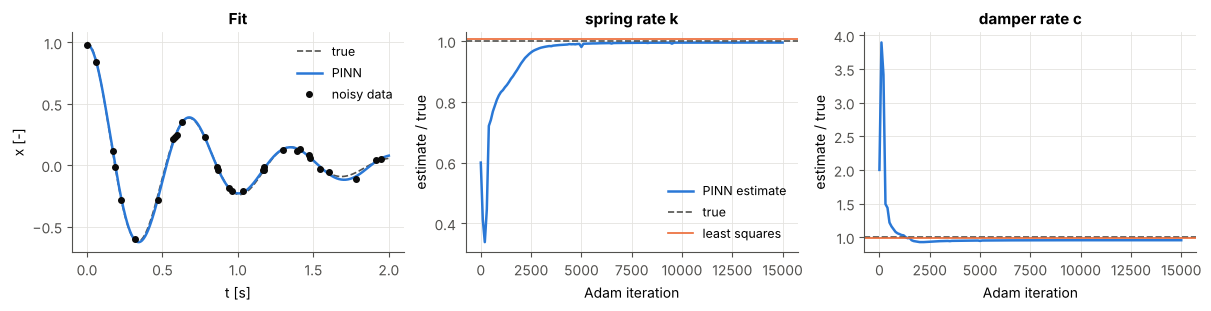

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
with torch.no_grad():
    x_inv = inv(Tp).numpy().ravel()
ax = axs[0]
ax.plot(t_plot, x_exact(t_plot), **REF, label="true")
ax.plot(t_plot, x_inv, color=C[0], label="PINN")
ax.plot(t_meas, x_meas, "o", color=INK, ms=4, label="noisy data")
ax.set_xlabel("t [s]"); ax.set_ylabel("x [-]"); ax.legend(); ax.set_title("Fit")
for ax, key, true, ls_val, name in [(axs[1], "k", k_true, k_ls, "spring rate k"),
                                     (axs[2], "c", c_true, c_ls, "damper rate c")]:
    ax.plot(h_inv["iter"], h_inv[key] / true, color=C[0], label="PINN estimate")
    ax.axhline(1, **REF, label="true")
    ax.axhline(ls_val / true, color=C[1], lw=1.2, label="least squares")
    ax.set_xlabel("Adam iteration"); ax.set_ylabel("estimate / true"); ax.set_title(name)
axs[1].legend()
plt.show()

Both routes recover $k$ and $c$ within a few percent (the PINN slightly less accurately on $c$). But look at the cost: the least-squares fit takes about half a second, the PINN tens of seconds plus a loss-weight choice (`LAM_INV`). For a **low-dimensional ODE with a cheap, reliable solver, classical least squares wins** – and it delivers error bars directly. (Try `LAM_INV = 1e-3` or `10` to see how the weighting changes the PINN result.)

Where the PINN formulation starts to pay off:

* the model is a **PDE** or has spatially distributed unknowns, so each "simulation" is expensive and there are many parameters (section 5);
* part of the equation is **unknown** and should be learned as a function (section 4);
* the inputs are **not fully known** (e.g. an unmeasured road or load profile) – a classical simulation cannot even be run, while the PINN only needs the residual where the physics is known;
* measurements are **scattered** in space and time, and you want a smooth, physically consistent reconstruction of all states, including unmeasured ones (velocity and acceleration come for free from $\hat x$).

## 4  Missing physics: learn an unknown damper characteristic

Now the damper force is an *unknown function* $F_d(v)$. The truth – unknown to the PINN – is a motorcycle-/car-like characteristic: rebound about three times stiffer than compression, degressive at high speed (blow-off):

$$F_d(v) = v_b \tanh(v/v_b)\,\big[c_c + (c_r - c_c)\,\sigma(v/v_s)\big].$$

Mass and spring rate are known (they are easy to measure), and so is the start of the test: released from $x=1$ at rest. The measurements are only displacements: 80 noisy samples of a free decay. The PINN contains **two networks**:

* $\hat x(t)$ – the response, with the initial conditions imposed exactly as in 2b;
* $\hat F_d(v) = v\cdot c_s\,\mathrm{softplus}\big(N_d(v)\big)$ – a small network for the damper force. The form guarantees $\hat F_d(0)=0$ and $\hat F_d(v)\,v \ge 0$: **a damper can only dissipate energy.**

Residual: $m\hat x'' + \hat F_d(\hat x') + k\hat x = 0$. The damper network is never shown a single force value – it is trained only through the equation. (We stay in normalised units, $m=1$, $k=\omega_0^2$, to keep the example compact.)

Training runs in **two stages**: first $\hat x$ alone is fitted to the data (a few seconds), then both networks are trained on data + physics. Both the dissipativity constraint and the warm start are there for a reason: a first version without them (free $\hat F_d$, joint training from random weights) found a degenerate solution – a huge force jump that made $\hat x$ nearly piecewise linear and ignored half of the data. With two networks there are many ways to make the residual small, and the physics has to rule out the unphysical ones.

In [12]:
c_r, c_c, v_b, v_s = 2 * 0.30 * w0, 2 * 0.08 * w0, 4.0, 0.3
def F_true(v):
    return v_b * np.tanh(v / v_b) * (c_c + (c_r - c_c) / (1 + np.exp(-v / v_s)))

T4 = 3.0
s4 = solve_ivp(lambda t, y: [y[1], -F_true(y[1]) - w0**2 * y[0]], (0, T4), [1.0, 0.0],
               dense_output=True, rtol=1e-9, atol=1e-11)
rng = np.random.default_rng(4)
t4 = np.sort(rng.uniform(0, T4, 80))
x4 = s4.sol(t4)[0] + 0.01 * rng.standard_normal(80)
t4_plot = np.linspace(0, T4, 500)
v_range = s4.sol(t4_plot)[1]
print(f"velocity range visited: {v_range.min():.2f} ... {v_range.max():.2f}")

class Response(torch.nn.Module):
    def __init__(self, T):
        super().__init__(); self.net, self.T = MLP(width=40), T
    def forward(self, t):
        s = 1 - torch.exp(-w0 * t)                       # hard IC: x(0)=1, x'(0)=0
        return 1 + s**2 * self.net(2 * t / self.T - 1)

class Damper(torch.nn.Module):
    # F(v) = v * c_s * softplus(N(v)):  F(0) = 0 and F*v >= 0 (dissipative) by construction
    def __init__(self, v_scale, c_scale):
        super().__init__(); self.net, self.vs, self.cs = MLP(width=16, depth=2), v_scale, c_scale
    def forward(self, v):
        return v * self.cs * torch.nn.functional.softplus(self.net(v / self.vs))

torch.manual_seed(0)
xnet, fnet = Response(T4), Damper(v_scale=8.0, c_scale=2 * 0.2 * w0)
T4_d, X4_d = to_t(t4), to_t(x4)
T4_c = to_t(np.linspace(0, T4, 300)).requires_grad_(True)

# stage 1: response network on the data only
h40 = train(list(xnet.parameters()),
            lambda: ((l := ((xnet(T4_d) - X4_d) ** 2).mean()), {"data": l}), n_iter=3000)

# stage 2: both networks, data + physics
def loss_missing():
    x = xnet(T4_c); xt = d(x, T4_c); xtt = d(xt, T4_c)
    r = (xtt + fnet(xt) + w0**2 * x) / w0**2
    l_d = ((xnet(T4_d) - X4_d) ** 2).mean()
    l_p = (r ** 2).mean()
    return l_d + 1.0 * l_p, {"data": l_d, "physics": l_p}

h4 = train(list(xnet.parameters()) + list(fnet.parameters()), loss_missing,
           n_iter=10000, lr_decay=0.8)
h4["time"] += h40["time"]
print(f"training time {h4['time']:.1f} s, final data loss {h4['data'][-1]:.1e} (noise variance 1e-4)")

velocity range visited: -8.85 ... 6.31


training time 50.5 s, final data loss 9.4e-05 (noise variance 1e-4)


damper force error inside the visited range: 2.8 % of the force span


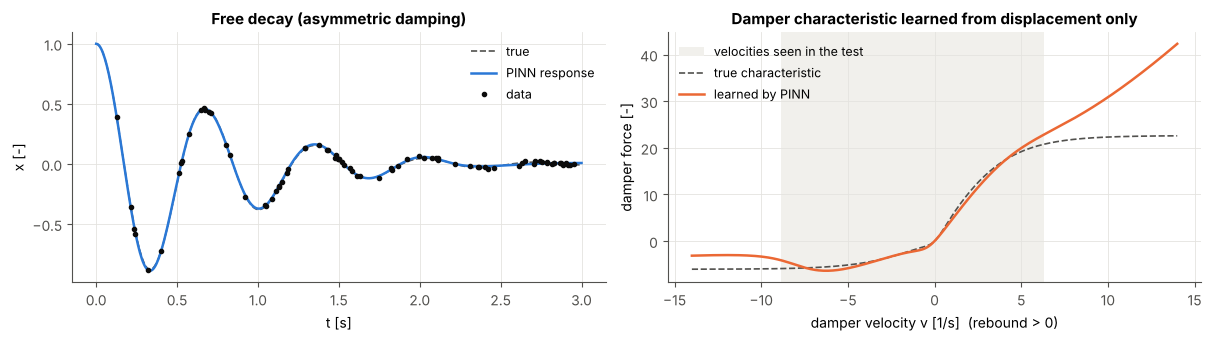

In [13]:
v_grid = np.linspace(-14, 14, 300)
with torch.no_grad():
    F_hat = fnet(to_t(v_grid)).numpy().ravel()
    x4_hat = xnet(to_t(t4_plot)).numpy().ravel()
inside = (v_grid >= v_range.min()) & (v_grid <= v_range.max())
rel = np.sqrt(np.mean((F_hat[inside] - F_true(v_grid[inside]))**2)) / np.ptp(F_true(v_grid[inside]))
print(f"damper force error inside the visited range: {100*rel:.1f} % of the force span")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
ax = axs[0]
ax.plot(t4_plot, s4.sol(t4_plot)[0], **REF, label="true")
ax.plot(t4_plot, x4_hat, color=C[0], label="PINN response")
ax.plot(t4, x4, "o", color=INK, ms=3, label="data")
ax.set_xlabel("t [s]"); ax.set_ylabel("x [-]"); ax.legend(); ax.set_title("Free decay (asymmetric damping)")
ax = axs[1]
ax.axvspan(v_range.min(), v_range.max(), color="#f1f0ec", lw=0, label="velocities seen in the test")
ax.plot(v_grid, F_true(v_grid), **REF, label="true characteristic")
ax.plot(v_grid, F_hat, color=C[1], label="learned by PINN")
ax.set_xlabel("damper velocity v [1/s]  (rebound > 0)"); ax.set_ylabel("damper force [-]")
ax.set_title("Damper characteristic learned from displacement only"); ax.legend(loc="upper left")
plt.show()

The asymmetry and the degressive shape are recovered inside the shaded band – the velocities the system actually passed through during the test. Near the edges of the band the agreement degrades: the extreme velocities are passed only once, for a short moment. Outside the band, the network has no information and simply extrapolates smoothly; that part of the curve means nothing. This is the general rule for any data-driven term: **a learned closure is only valid on the states the experiment excited.** Test design (here: initial deflection, or several decays with different amplitudes) decides what can be learned.

The same pattern applies to many tasks in vehicle and engine simulation where most of the model is trusted and one element is not: a tyre relaxation term, a friction law in a damper or clutch, a bushing hysteresis, a heat-transfer coefficient. The hybrid structure keeps the known physics exact and gives the network only the job it cannot be avoided for. Once the curve is learned, it can be **fitted with a parametric law** (a polynomial, a Magic-Formula-type expression) and moved into the Dymola/Modelica model.

## 5  A PDE: temperature field and diffusivity from three sensors

PINNs were designed for PDEs, and this is where the inverse formulation is strongest. 1-D heat conduction in a rod, non-dimensional, ends held at zero:

$$u_t = \alpha\,u_{xx},\qquad u(0,t)=u(1,t)=0,\qquad x\in[0,1],\ t\in[0,1].$$

The truth has $\alpha = 0.1$ and an initial profile $u(x,0) = \sin\pi x + 0.5\sin 3\pi x$. The PINN is told the PDE and the boundary conditions, but **neither $\alpha$ nor the initial condition**. Its only data: three "thermocouples" at $x = 0.2, 0.45, 0.8$, sampled 25 times each with noise. From that, it should reconstruct the complete field $u(x,t)$ and $\alpha$.

The network now has two inputs $(x,t)$; the boundary conditions are imposed exactly by $\hat u = x(1-x)\,N(x,t)$; the residual needs $\partial_t \hat u$ and $\partial_{xx}\hat u$ – the same `d` helper applied to the right input column.

In [14]:
alpha_true = 0.1
def u_exact(x, t):
    return (np.exp(-alpha_true * np.pi**2 * t) * np.sin(np.pi * x)
            + 0.5 * np.exp(-9 * alpha_true * np.pi**2 * t) * np.sin(3 * np.pi * x))

rng = np.random.default_rng(5)
x_s = np.array([0.2, 0.45, 0.8])
t_s = np.linspace(0, 1, 25)
XS, TS = np.meshgrid(x_s, t_s)
u_s = u_exact(XS, TS) + 0.01 * rng.standard_normal(XS.shape)
XT_d = torch.tensor(np.c_[XS.ravel(), TS.ravel()])
U_d = to_t(u_s.ravel())

class Field(torch.nn.Module):
    def __init__(self):
        super().__init__(); self.net = MLP(n_in=2, width=32, depth=4)
    def forward(self, x, t):
        return x * (1 - x) * self.net(torch.cat([2 * x - 1, 2 * t - 1], dim=1))

torch.manual_seed(0)
field = Field()
log_alpha = torch.tensor([np.log(0.03)], requires_grad=True)     # initial guess alpha = 0.03
sob = torch.quasirandom.SobolEngine(2, scramble=True, seed=0).draw(1500).double()
xc, tc = sob[:, :1].clone().requires_grad_(True), sob[:, 1:].clone().requires_grad_(True)

def loss_heat():
    u = field(xc, tc)
    r = d(u, tc) - torch.exp(log_alpha) * d(d(u, xc), xc)
    l_d = ((field(XT_d[:, :1], XT_d[:, 1:]) - U_d) ** 2).mean()
    l_p = (r ** 2).mean()
    return l_d + 0.1 * l_p, {"data": l_d, "physics": l_p, "alpha": torch.exp(log_alpha)}

h5 = train([{"params": field.parameters()}, {"params": [log_alpha], "lr": 1e-2}], loss_heat,
           n_iter=8000, lr_decay=0.8)
print(f"alpha: true {alpha_true}, PINN {h5['alpha'][-1]:.4f}   [{h5['time']:.1f} s]")

alpha: true 0.1, PINN 0.1006   [73.4 s]


field RMS error 0.0049  (field max 1.08, sensor noise 0.01)


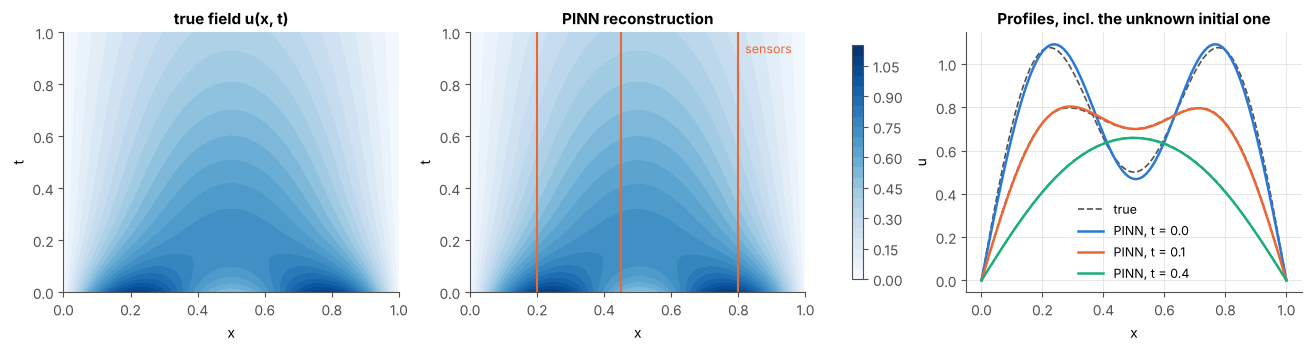

In [15]:
xg, tg = np.linspace(0, 1, 101), np.linspace(0, 1, 101)
XG, TG = np.meshgrid(xg, tg)
with torch.no_grad():
    U_hat = field(to_t(XG.ravel()), to_t(TG.ravel())).numpy().reshape(XG.shape)
U_ex = u_exact(XG, TG)
print(f"field RMS error {np.sqrt(np.mean((U_hat - U_ex)**2)):.4f}  (field max {U_ex.max():.2f}, sensor noise 0.01)")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
lv = np.linspace(0, 1.15, 24)
for ax, U, ttl in [(axs[0], U_ex, "true field u(x, t)"), (axs[1], U_hat, "PINN reconstruction")]:
    cs = ax.contourf(XG, TG, U, levels=lv, cmap="Blues")
    ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_title(ttl); ax.grid(False)
for xi in x_s:
    axs[1].axvline(xi, color=C[1], lw=1.5)
axs[1].text(0.82, 0.92, "sensors", color=C[1], fontsize=9)
fig.colorbar(cs, ax=axs[:2], shrink=0.9)
ax = axs[2]
for i, tt in enumerate([0.0, 0.1, 0.4]):
    j = np.argmin(abs(tg - tt))
    ax.plot(xg, U_ex[j], **REF, label="true" if i == 0 else None)
    ax.plot(xg, U_hat[j], color=C[i], label=f"PINN, t = {tt}")
ax.set_xlabel("x"); ax.set_ylabel("u"); ax.set_title("Profiles, incl. the unknown initial one"); ax.legend()
plt.show()

From 75 noisy point measurements, the PINN recovers the diffusivity and a full space-time field, including the initial profile that it was never told – the PDE links what the three sensors see to everything in between. Doing the same classically means parametrising the unknown initial condition (a Fourier series, say), running a PDE solver inside an optimiser, and tuning the parametrisation – entirely possible, but more work to set up. This kind of task (sparse sensors, field-type quantity, unknown coefficients) is the sweet spot of PINNs; the engine-side analogues are temperature fields in a cylinder head or brake disc from a few thermocouples, or a heat-transfer coefficient identified from them.

The largest deviations are in the initial profile ($t = 0$, blue curve): the fast $\sin 3\pi x$ mode decays within a few sensor samples, so there is little information about it – again, the data decide what can be identified.

## 6  When is a PINN worth it? – an assessment for vehicle-dynamics and engine work

| Task | Better tool | Why |
|---|---|---|
| Simulate a known ODE/DAE model (MBS, driveline, quasi-static vehicle) | classical solver (Dymola, `solve_ivp`) | orders of magnitude faster and more accurate (section 2b) |
| Calibrate a few parameters of a cheap, trusted ODE model | least squares on the solver (calibration course, nb 03) | fast, error bars for free, no loss weights (section 3) |
| Calibrate when each run is expensive, many evaluations | surrogate + optimisation (calibration course, nb 04/06) | a PINN still needs the physics in differentiable form |
| One element of the model unknown (damper, friction, tyre transient, bushing) | **PINN with a neural closure**, or a differentiable solver with a neural term | learns a *function* through the equation from indirect measurements (section 4) |
| Field quantity from sparse sensors, unknown coefficients / initial or boundary data | **PINN** | mesh-free, one optimisation for field + parameters (section 5) |
| Inputs not fully measured (road profile, load) but the dynamics are trusted | **PINN** (unknown input as another network) | a forward simulation cannot even be run |

**Practical rules that decide success or failure**

1. **Non-dimensionalise** inputs, outputs and the residual so that every term is $\mathcal O(1)$. Most "PINN does not train" reports are scaling problems.
2. **Smooth activations** (tanh), double precision, and impose initial/boundary conditions as hard constraints where possible.
3. **Loss weights** ($\lambda$) matter when data and physics disagree (noise, model error). Inspect both loss terms separately, never just the total.
4. **Long horizons and high frequencies are hard** (spectral bias: networks learn low frequencies first). Split the time axis into windows, use time-marching, or Fourier-feature inputs.
5. **Check identifiability classically.** A parameter that is not identifiable from the data (calibration course, nb 02) does not become identifiable because a network is involved – the PINN just returns *a* value, without error bars.
6. **Validate against a classical simulation** whenever one exists, and only trust learned closures inside the excited state range.

**Closely related alternative.** For ODE systems such as vehicle or driveline models, the *differentiable-solver* route – "neural ODE" / "universal differential equation": an ODE integrator in PyTorch (e.g. `torchdiffeq`) with a neural network for the unknown term, trained through the integrator – is often more robust than a PINN, because the dynamics are integrated rather than penalised. It is the natural next step from section 4 and from the "rewrite the model in PyTorch" item in the calibration course.

**Libraries**, once the basics are clear: *DeepXDE* (compact PINN library, many PDE examples), *NVIDIA PhysicsNeMo* (formerly Modulus; large-scale), *torchdiffeq* (neural ODEs). For learning, the hand-written ~20 lines per example above are more instructive.

## Exercises

1. **Fewer data.** In 2a, reduce the measured window to 0.3 s or to 4 points. When does the PINN extrapolation fail?
2. **Long horizon.** In 2b, set `T_END = 6` (9 periods). Watch the PINN converge to a wrong, quickly decaying solution. Fix it by time-windowing: train on $[0,2]$, use its end state as the initial condition for $[2,4]$, and so on.
3. **Model error.** In section 3, generate the data with a small cubic spring term $k_3 x^3$ but keep the linear residual. How do the estimated $k$, $c$ and the two loss terms react, compared with the least-squares fit? (Compare with notebook 03, data set B.)
4. **Test design.** In section 4, add a second free decay with initial deflection 0.4 (a second output of the response network, or a second response network sharing the same damper network). How much of the characteristic becomes identifiable?
5. **Unknown input.** In section 3, add a base excitation $z(t)$ to the equation, $m\ddot x + c(\dot x-\dot z) + k(x-z) = 0$, with $z(t)$ unknown and represented by a third network. What do you need to know (or assume) for $c$, $k$ and $z$ to be identifiable?